In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import tqdm
import os
import glob
import cv2
from sklearn.model_selection import train_test_split

from tensorflow.keras import backend as keras
from tensorflow.keras.callbacks import Callback, ModelCheckpoint,ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Read from TFRecords

34898 34898
Training samples: 27918
Validation samples: 3490
Test samples: 3490


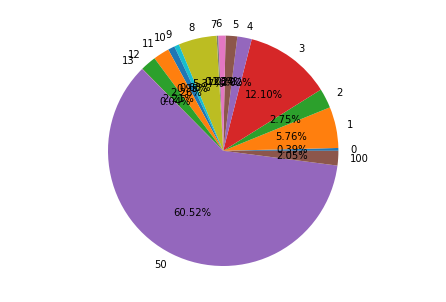

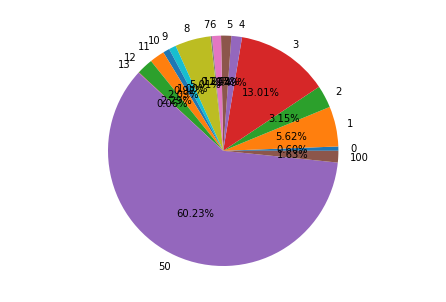

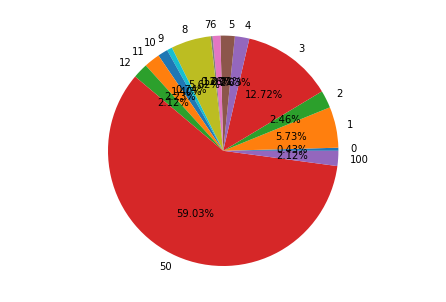

In [ ]:
def read_tfrecord(example):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),  # tf.string = bytestring (not text string)
        "label": tf.io.VarLenFeature(tf.float32),
        "mask": tf.io.FixedLenFeature([], tf.string),        # a certain number of floats0
        "w_label":  tf.io.FixedLenFeature([], tf.int64),  # one integers
        "w_segm":  tf.io.FixedLenFeature([], tf.int64),
    }

    # decode the TFRecord
    example = tf.io.parse_single_example(example, features)

    image = tf.image.decode_jpeg(example['image'], channels=3)
    label = tf.sparse.to_dense(example['label'])
    mask  = tf.image.decode_jpeg(example['mask'], channels=3)

    weights = [ tf.cast(example['w_label'], tf.float32), tf.cast(example['w_segm'], tf.float32)]

    # label  = tf.reshape(tf.sparse.to_dense(example['label']), [-1, 14])
    height = 224,#example['size'][0]
    width  = 224,#example['size'][1]
    image = tf.cast(tf.reshape(image, [224,224,3]),tf.float64)
    mask = tf.cast(tf.reshape(tf.reshape(mask, [224,224,3])[:,:,0],[224,224,1]),tf.float64)
    return image, (label,mask), (example['w_label'],example['w_segm'])


GCS_OUTPUT = '/content/drive/MyDrive/Proyecto RxTx/Chest Xray14 Tfrecord/'

meta = pd.read_csv("/content/drive/MyDrive/Proyecto RxTx/ChestRay/Images_segmentation_mask (3).csv")
meta = meta[meta['View Position'] == 'AP']

labels = np.array(meta[['Atelectasis','Consolidation','Infiltration','Pneumothorax','Edema','Emphysema','Fibrosis','Effusion','Pneumonia','Pleural_Thickening','Cardiomegaly','Nodule','Mass','Hernia']])
w_label	= meta['w_label']
w_segm = meta['w_segm']
y = []
for l,wl,ws in zip(labels,w_label,w_segm):
  if ws==1.0:
    y.append(100)
  else:
    pos = np.where(l)[0]
    if len(pos)==0:
      y.append(50)
    else:
      y.append(pos[0])


filenames = [GCS_OUTPUT + "{:02d}-{}.tfrec".format(shard, 1) for shard in range(len(y))]

print(len(filenames),len(y))

filenames_train, filenames_test, y_train, y_test = train_test_split(filenames, y, test_size=0.2, random_state=1, shuffle=True)

filenames_test, filenames_val, y_test, y_val  = train_test_split(filenames_test, y_test, test_size=0.5, random_state=1, shuffle=True) # 0.25 x 0.8 = 0.2

print('Training samples:',len(filenames_train))
print('Validation samples:',len(filenames_val))
print('Test samples:',len(filenames_test))

for a in [y_train,y_val,y_test]:
  u, c = np.unique(a,return_counts=True)
  fig = plt.figure()
  ax = fig.add_axes([0,0,1,1])
  ax.axis('equal')
  ax.pie(c, labels = u,autopct='%1.2f%%')
  plt.show()

In [ ]:
# read from TFRecords. For optimal performance, read from multiple
# TFRecord files at once and set the option experimental_deterministic = False
# to allow order-altering optimizations.

option_no_order = tf.data.Options()
option_no_order.experimental_deterministic = False

train_dsr = tf.data.TFRecordDataset(filenames_train, num_parallel_reads=tf.data.experimental.AUTOTUNE)
train_dsr = train_dsr.shuffle(512)
train_dsr = train_dsr.with_options(option_no_order)
train_dsr = train_dsr.map(read_tfrecord, num_parallel_calls=tf.data.experimental.AUTOTUNE)
train_dsr =train_dsr.batch(64).prefetch(1)

val_dsr = tf.data.TFRecordDataset(filenames_val, num_parallel_reads=tf.data.experimental.AUTOTUNE)
val_dsr = val_dsr.with_options(option_no_order)
val_dsr = val_dsr.map(read_tfrecord, num_parallel_calls=tf.data.experimental.AUTOTUNE)

test_dsr = tf.data.TFRecordDataset(filenames_test, num_parallel_reads=tf.data.experimental.AUTOTUNE)
test_dsr = test_dsr.with_options(option_no_order)
test_dsr = test_dsr.map(read_tfrecord, num_parallel_calls=tf.data.experimental.AUTOTUNE)

# Carga del modelo híbrido

In [ ]:
def dice_coef(y_true, y_pred):
    y_true_f =  keras.flatten(y_true)
    y_pred_f =  keras.flatten(y_pred)
    intersection = keras.sum(y_true_f * y_pred_f)
    result = (2. * intersection + 1.) / ((keras.sum(y_true_f) + keras.sum(y_pred_f) + 1.))
    return (result)

def dice_coef_loss(y_true, y_pred):
    return -dice_coef(y_true, y_pred)

In [ ]:
new_model = tf.keras.models.load_model('/content/drive/MyDrive/Proyecto RxTx/my_model.h5', custom_objects={'dice_coef':dice_coef,'dice_coef_loss': dice_coef_loss})

In [ ]:
# new_model.summary()

In [ ]:
weight_path="/content/drive/MyDrive/Proyecto RxTx/checkpoints/{}_weights.best.hdf5".format('cxr_Hibryd_DenseNet_metodo1_00')
checkpoint = ModelCheckpoint(weight_path, monitor='loss', verbose=1,
                             save_best_only=True, mode='min', save_weights_only = True)

reduceLROnPlat = ReduceLROnPlateau(monitor='loss', factor=0.5,
                                   patience=3,
                                   verbose=1, mode='min', min_delta=0.0001, cooldown=2, min_lr=1e-6)
#early = EarlyStopping(monitor="val_loss",
#
callbacks_list = [checkpoint, reduceLROnPlat]

wl =704/34898

ws = 1-wl
#Peso de las funciones de perdida
lossWeights = {'dense': wl, 'segm': ws}

new_model.compile(optimizer=Adam(learning_rate=2e-5),
                  loss={'dense': 'binary_crossentropy',
                        'segm':  dice_coef_loss,},
                 metrics={'dense':['accuracy', tf.keras.metrics.AUC(multi_label=True)],
                          'segm': [dice_coef, 'binary_accuracy']
                          },
                    loss_weights =  lossWeights )

In [ ]:
loss_history = new_model.fit(train_dsr, epochs=300, steps_per_epoch=64, callbacks=callbacks_list, verbose=1)

## Revisar y comparar

https://github.com/guide2157/ChulaXrayClassifier/blob/master/Baseline%20Training/AGCNNTrain.ipynb


In [ ]:
def preprocess_image(image):
  image = tf.cast(image, tf.float32)
  image = image / 255.
  image_net_mean = np.array([0.485, 0.456, 0.406])
  image_net_std = np.array([0.229, 0.224, 0.225])
  image = tf.math.subtract(image, image_net_mean)
  image = tf.math.divide(image, image_net_std)
  return image
def preprocess_image_dataset(image, label):
  return preprocess_image(image), label

train_dsrr = train_dsr.batch(BS).map(preprocess_image_dataset, num_parallel_calls=tf.data.experimental.AUTOTUNE).prefetch(tf.data.experimental.AUTOTUNE)